# Проект «Plants & Gardens»

**Автор:** Алексей Булычев


**Контекст:** Компания разрабатывает мобильные игры. Менеджер поставил задачи по исследованию нескольких аспектов приложения.

**Задачи проекта:**

- Retention (удержание игроков). Написать функцию на Python для расчёта retention по дням от даты регистрации игрока. Данные: `problem1-reg_data.csv` (время регистрации) и `problem1-auth_data.csv` (время заходов в игру).

- A/B-тестирование акционных предложений. По результатам теста двух групп (контрольной и тестовой) определить, какой набор акционных предложений лучше. Известно: ARPU в тестовой группе выше на 5%, при этом платящих в контрольной — 1928 из 202103, в тестовой — 1805 из 202667. Требуется выбрать метрики для принятия решения и обосновать выбор.

    Формат данных для A/B-теста: `user_id`, `revenue`, `testgroup (a/b)`.

- Метрики для тематического события. Предложить метрики оценки результатов последнего прошедшего события в игре Plants & Gardens. Дополнительно: оценить, как изменится набор метрик, если усложнить механику — при неудачной попытке выполнения уровня игрок откатывается на несколько уровней назад.



## Оглавление

1. [Импорт библиотек и чтение данных](#section-1)
2. [Разведочный анализ данных](#section-2)
3. [Задача 1. Функция для расчета Retention](#section-3)
4. [Выводы по задаче 1](#section-4)
5. [Задача 2. A/B тест](#section-5)
6. [Выводы по задаче 2](#section-6)
7. [Задача 3. Метрики тематического события в игре Plants & Gardens](#section-7)


## Импорт библиотек и чтение данных <a id="section-1"></a>

In [1]:
# Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Данные по Задаче 1 - Читаю csv и сохраняю в переменные, разделитель ';'
reg_data = pd.read_csv('data/problem1-reg_data.csv', sep=';')
auth_data = pd.read_csv('data/problem1-auth_data.csv', sep=';')

# Данные по Задаче 2 - Читаю данные, смотрю разделитель, добавляю sep=';'
df_ab = pd.read_csv('data/A-B_test_results.csv', sep=';')

## Разведочный анализ данных <a id="section-2"></a>

In [3]:
# Кол-во строк и столбцов в reg_data
reg_data.shape

(1000000, 2)

In [4]:
# Типы данных reg_data
reg_data.dtypes

reg_ts    int64
uid       int64
dtype: object

In [5]:
# Смотрю первые строки
reg_data.head()

,reg_ts,uid
0,911382223,1
1,932683089,2
2,947802447,3
3,959523541,4
4,969103313,5


In [6]:
# Проверяю пропущенные значения
reg_data.isna().sum()

reg_ts    0
uid       0
dtype: int64

In [7]:
# Смотрю количество уникальных id пользователей
reg_data['uid'].nunique()

1000000

In [8]:
# Кол-во столбцов и строк в auth_data   
auth_data.shape

(9601013, 2)

In [9]:
# Типы данных в auth_data
auth_data.dtypes

auth_ts    int64
uid        int64
dtype: object

In [10]:
# Смотрю первые несколько строк
auth_data.head()

,auth_ts,uid
0,911382223,1
1,932683089,2
2,932921206,2
3,933393015,2
4,933875379,2


In [11]:
# Проверка на пропущенные занчения
auth_data.isna().sum()

auth_ts    0
uid        0
dtype: int64

In [12]:
# Униакальные id пользователей в auth_data
auth_data['uid'].nunique()

1000000

Столбцы `reg_ts` и `auth_ts` содержат информацию о дате и времени в формате Unix-timestamp, которые необходимо преобразовать с помощью `pd.to_datetime()`

Так как необходимо посчитать retention по дням, то использую `dt.normalize()`, чтобы отбросить часы, минуты, секунды и оставить только дату и работать по дням

In [13]:
reg_data['reg_date'] = pd.to_datetime(reg_data['reg_ts'], unit='s').dt.normalize()
reg_data

,reg_ts,uid,reg_date
0,911382223,1,1998-11-18
1,932683089,2,1999-07-22
2,947802447,3,2000-01-13
3,959523541,4,2000-05-28
4,969103313,5,2000-09-16
...,...,...,...
999995,1600874034,1110618,2020-09-23
999996,1600874086,1110619,2020-09-23
999997,1600874139,1110620,2020-09-23
999998,1600874191,1110621,2020-09-23


In [14]:
auth_data['auth_date'] = pd.to_datetime(auth_data['auth_ts'], unit='s').dt.normalize()
auth_data

,auth_ts,uid,auth_date
0,911382223,1,1998-11-18
1,932683089,2,1999-07-22
2,932921206,2,1999-07-25
3,933393015,2,1999-07-31
4,933875379,2,1999-08-05
...,...,...,...
9601008,1600874034,1110618,2020-09-23
9601009,1600874086,1110619,2020-09-23
9601010,1600874139,1110620,2020-09-23
9601011,1600874191,1110621,2020-09-23


In [15]:
# Присоединяю к каждому заходу в приложение дату регистрации этого пользователя
auth_merged = auth_data.merge(
    reg_data[['uid', 'reg_date']],
    on='uid',
    how='left'
)
auth_merged

,auth_ts,uid,auth_date,reg_date
0,911382223,1,1998-11-18,1998-11-18
1,932683089,2,1999-07-22,1999-07-22
2,932921206,2,1999-07-25,1999-07-22
3,933393015,2,1999-07-31,1999-07-22
4,933875379,2,1999-08-05,1999-07-22
...,...,...,...,...
9601008,1600874034,1110618,2020-09-23,2020-09-23
9601009,1600874086,1110619,2020-09-23,2020-09-23
9601010,1600874139,1110620,2020-09-23,2020-09-23
9601011,1600874191,1110621,2020-09-23,2020-09-23


In [16]:
# Проверки на правильность merge
print("auth_data shape:", auth_data.shape)
print("auth_merged shape:", auth_merged.shape)
print()
print(auth_merged.head())
print()

# Считаю пропуски в reg_date - проверяю не было ли вдруг каких-то авторизаций без регистрации
print("Пропуски в reg_date:", auth_merged['reg_date'].isna().sum())

auth_data shape: (9601013, 3)
auth_merged shape: (9601013, 4)

     auth_ts  uid  auth_date   reg_date
0  911382223    1 1998-11-18 1998-11-18
1  932683089    2 1999-07-22 1999-07-22
2  932921206    2 1999-07-25 1999-07-22
3  933393015    2 1999-07-31 1999-07-22
4  933875379    2 1999-08-05 1999-07-22

Пропуски в reg_date: 0


Количество строк не изменилось, столбец `reg_date` добавлен, пропусков в `reg_date` нет

In [17]:
# Считаю разницу в количестве дней между авторизацией и регистрацией
auth_merged['day_since_reg'] = (auth_merged['auth_date'] - auth_merged['reg_date']).dt.days
auth_merged

,auth_ts,uid,auth_date,reg_date,day_since_reg
0,911382223,1,1998-11-18,1998-11-18,0
1,932683089,2,1999-07-22,1999-07-22,0
2,932921206,2,1999-07-25,1999-07-22,3
3,933393015,2,1999-07-31,1999-07-22,9
4,933875379,2,1999-08-05,1999-07-22,14
...,...,...,...,...,...
9601008,1600874034,1110618,2020-09-23,2020-09-23,0
9601009,1600874086,1110619,2020-09-23,2020-09-23,0
9601010,1600874139,1110620,2020-09-23,2020-09-23,0
9601011,1600874191,1110621,2020-09-23,2020-09-23,0


In [18]:
# Смотрю min - max в day_since_reg
print("Min day_since_reg:", auth_merged['day_since_reg'].min())
print("Max day_since_reg:", auth_merged['day_since_reg'].max())

Min day_since_reg: 0
Max day_since_reg: 7729


In [19]:
daily_users = auth_merged.groupby('day_since_reg')['uid'].nunique()
daily_users.head(20)

day_since_reg
0     1000000
1       20071
2       40997
3       46338
4       52258
5       59863
6       68194
7       58140
8       47335
9       50222
10      50759
11      50814
12      49891
13      48154
14      44726
15      44711
16      43781
17      42721
18      41278
19      39901
Name: uid, dtype: int64

In [20]:
# Проверка: есть ли пользователи, которые зарегистрировались, но ни разу не зашли
reg_uids = set(reg_data['uid'])
auth_uids = set(auth_data['uid'])

lost_users = reg_uids - auth_uids

print(f"Пользователей, зарегистрированных, но ни разу не зашедших: {len(lost_users)}")
if len(lost_users) > 0:
    print("Внимание: эти пользователи не попадут в auth_merged, но учтены в знаменателе (cohort_sizes).")
else:
    print("Все зарегистрированные пользователи имеют хотя бы одну авторизацию. Потерь при merge нет.")

Пользователей, зарегистрированных, но ни разу не зашедших: 0
Все зарегистрированные пользователи имеют хотя бы одну авторизацию. Потерь при merge нет.


In [21]:
# Проверка на потерю пользователей при merge
reg_uids = set(reg_data['uid'])
auth_uids = set(auth_data['uid'])

# Пользователи, которые зарегистрировались, но ни разу не зашли 
lost_users = reg_uids - auth_uids

print(f"Уникальных uid в reg_data: {len(reg_uids)}")
print(f"Уникальных uid в auth_data: {len(auth_uids)}")
print(f"Пользователей, которые зарегистрировались, но ни разу не зашли: {len(lost_users)}")

if len(lost_users) > 0:
    print("Внимание: эти пользователи не попадут в auth_merged")
else:
    print("Все зарегистрированные пользователи имеют хотя бы одну авторизацию. Потерь нет.")

Уникальных uid в reg_data: 1000000
Уникальных uid в auth_data: 1000000
Пользователей, которые зарегистрировались, но ни разу не зашли: 0
Все зарегистрированные пользователи имеют хотя бы одну авторизацию. Потерь нет.


## Задача 1. Функция для расчета Retention <a id="section-3"></a>

In [22]:
# Копирую только нужные изначально доступные колонки в исходных таблицах  
reg_copy = reg_data[['uid', 'reg_ts']].copy()
auth_copy = auth_data[['uid', 'auth_ts']].copy()

# Unix-timestamp перевожу в дату
reg_copy['reg_date'] = pd.to_datetime(reg_copy['reg_ts'], unit='s').dt.normalize()
auth_copy['auth_date'] = pd.to_datetime(auth_copy['auth_ts'], unit='s').dt.normalize()


In [23]:
# Проверяю результат
print("reg_copy shape:", reg_copy.shape)
print("auth_copy shape:", auth_copy.shape)
print()
print(reg_copy.head())
print()
print(auth_copy.head())
print()
print(reg_copy.dtypes)
print()
print(auth_copy.dtypes)

reg_copy shape: (1000000, 3)
auth_copy shape: (9601013, 3)

   uid     reg_ts   reg_date
0    1  911382223 1998-11-18
1    2  932683089 1999-07-22
2    3  947802447 2000-01-13
3    4  959523541 2000-05-28
4    5  969103313 2000-09-16

   uid    auth_ts  auth_date
0    1  911382223 1998-11-18
1    2  932683089 1999-07-22
2    2  932921206 1999-07-25
3    2  933393015 1999-07-31
4    2  933875379 1999-08-05

uid                 int64
reg_ts              int64
reg_date    datetime64[s]
dtype: object

uid                  int64
auth_ts              int64
auth_date    datetime64[s]
dtype: object


In [24]:
# Присоединяю к каждой авторизации дату регистрации пользователя
auth_merged = auth_copy.merge(
    reg_copy[['uid', 'reg_date']],
    on='uid',
    how='left'
)

In [25]:
print("auth_merged shape:", auth_merged.shape)
print()
print("auth_merged head:")
display(auth_merged.head(10))
print()
print("Пропуски в reg_date:", auth_merged['reg_date'].isna().sum())

auth_merged shape: (9601013, 4)

auth_merged head:


,uid,auth_ts,auth_date,reg_date
0,1,911382223,1998-11-18,1998-11-18
1,2,932683089,1999-07-22,1999-07-22
2,2,932921206,1999-07-25,1999-07-22
3,2,933393015,1999-07-31,1999-07-22
4,2,933875379,1999-08-05,1999-07-22
5,2,934372615,1999-08-11,1999-07-22
6,2,934662633,1999-08-14,1999-07-22
7,2,935002586,1999-08-18,1999-07-22
8,2,935141232,1999-08-20,1999-07-22
9,2,935682752,1999-08-26,1999-07-22



Пропуски в reg_date: 0


In [26]:
auth_merged['day_since_reg'] = (auth_merged['auth_date'] - auth_merged['reg_date']).dt.days

In [27]:
print("Min day_since_reg:", auth_merged['day_since_reg'].min())
print("Max day_since_reg:", auth_merged['day_since_reg'].max())
print()
print("Уникальных значений:", auth_merged['day_since_reg'].nunique())
print()
print("Первые строки:")
print(auth_merged[['uid', 'reg_date', 'auth_date', 'day_since_reg']].head(10))
print()
print("Пропуски в day_since_reg:", auth_merged['day_since_reg'].isna().sum())

Min day_since_reg: 0
Max day_since_reg: 7729

Уникальных значений: 5916

Первые строки:
   uid   reg_date  auth_date  day_since_reg
0    1 1998-11-18 1998-11-18              0
1    2 1999-07-22 1999-07-22              0
2    2 1999-07-22 1999-07-25              3
3    2 1999-07-22 1999-07-31              9
4    2 1999-07-22 1999-08-05             14
5    2 1999-07-22 1999-08-11             20
6    2 1999-07-22 1999-08-14             23
7    2 1999-07-22 1999-08-18             27
8    2 1999-07-22 1999-08-20             29
9    2 1999-07-22 1999-08-26             35

Пропуски в day_since_reg: 0


In [28]:
# Кол-во пользователей сгруппированное по дате регистрации и количеству дней после регистрации
counts = (
    auth_merged
    .groupby(['reg_date', 'day_since_reg'])['uid']
    .nunique()
    .reset_index(name='n_users')
)
counts

,reg_date,day_since_reg,n_users
0,1998-11-18,0,1
1,1999-07-22,0,1
2,1999-07-22,3,1
3,1999-07-22,9,1
4,1999-07-22,14,1
...,...,...,...
2716223,2020-09-21,1,31
2716224,2020-09-21,2,49
2716225,2020-09-22,0,1641
2716226,2020-09-22,1,14


In [29]:
print(counts.dtypes)
print()
print("Сумма n_users:", counts['n_users'].sum())

reg_date         datetime64[s]
day_since_reg            int64
n_users                  int64
dtype: object

Сумма n_users: 9601013


In [30]:
pivot = counts.pivot(
    index='reg_date',         # строки
    columns='day_since_reg',  # столбцы
    values='n_users',         # ячейки
)
pivot

day_since_reg,0,1,2,3,4,5,6,7,8,9,...,7701,7704,7706,7709,7712,7716,7720,7721,7727,7729
reg_date,,,,,,,,,,,,,,,,,,,,,
1998-11-18,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-07-22,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2000-01-13,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-05-28,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-09-16,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-19,1634.0,30.0,58.0,77.0,57.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-20,1636.0,40.0,71.0,39.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-21,1638.0,31.0,49.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
print("pivot shape:", pivot.shape)
print()
print("pivot head (первые 5 когорт, первые 10 дней):")
print(pivot.iloc[:5, :10])
print()
print("Тип индекса:", pivot.index.dtype)
print("Тип столбцов:", pivot.columns.dtype)
print("Мин. столбец:", pivot.columns.min())
print("Макс. столбец:", pivot.columns.max())

pivot shape: (5110, 5916)

pivot head (первые 5 когорт, первые 10 дней):
day_since_reg    0   1   2    3   4   5   6   7   8    9
reg_date                                                
1998-11-18     1.0 NaN NaN  NaN NaN NaN NaN NaN NaN  NaN
1999-07-22     1.0 NaN NaN  1.0 NaN NaN NaN NaN NaN  1.0
2000-01-13     1.0 NaN NaN  NaN NaN NaN NaN NaN NaN  NaN
2000-05-28     1.0 NaN NaN  NaN NaN NaN NaN NaN NaN  NaN
2000-09-16     1.0 NaN NaN  NaN NaN NaN NaN NaN NaN  NaN

Тип индекса: datetime64[s]
Тип столбцов: int64
Мин. столбец: 0
Макс. столбец: 7729


In [32]:
# Считаю уникальных uid по каждой дате регистрации
cohort_sizes = reg_copy.groupby('reg_date')['uid'].nunique()

In [33]:
print("cohort_sizes shape:", cohort_sizes.shape)
print()
print("cohort_sizes head:")
print(cohort_sizes.head(10))
print()
print("cohort_sizes tail:")
print(cohort_sizes.tail(10))
print()
print("Сумма размеров когорт:", cohort_sizes.sum())
print()
print("Уникальных uid в reg_copy:", reg_copy['uid'].nunique())
print()
print("Совпадает ли сумма с числом uid:", cohort_sizes.sum() == reg_copy['uid'].nunique())

cohort_sizes shape: (5110,)

cohort_sizes head:
reg_date
1998-11-18    1
1999-07-22    1
2000-01-13    1
2000-05-28    1
2000-09-16    1
2000-12-19    1
2001-03-10    1
2001-05-21    1
2001-07-24    1
2001-09-20    1
Name: uid, dtype: int64

cohort_sizes tail:
reg_date
2020-09-14    1619
2020-09-15    1623
2020-09-16    1625
2020-09-17    1628
2020-09-18    1630
2020-09-19    1634
2020-09-20    1636
2020-09-21    1638
2020-09-22    1641
2020-09-23    1048
Name: uid, dtype: int64

Сумма размеров когорт: 1000000

Уникальных uid в reg_copy: 1000000

Совпадает ли сумма с числом uid: True


In [34]:
# Retention - делим каждую строку pivot на размер её когорты
retention_matrix = pivot.divide(cohort_sizes, axis=0)
retention_matrix

day_since_reg,0,1,2,3,4,5,6,7,8,9,...,7701,7704,7706,7709,7712,7716,7720,7721,7727,7729
reg_date,,,,,,,,,,,,,,,,,,,,,
1998-11-18,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-07-22,1.0,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2000-01-13,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-05-28,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-09-16,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-19,1.0,0.018360,0.035496,0.047124,0.034884,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-20,1.0,0.024450,0.043399,0.023839,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-21,1.0,0.018926,0.029915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
#Собираю функцию

def retention(reg_data, auth_data, start_date=None, end_date=None, day=None, as_percent=False):
    """
    Считает когортный retention по дням от даты регистрации.
    
    Параметры:
    ----------
    reg_data : pd.DataFrame
        Таблица с регистрациями. Должна содержать колонки 'uid' и 'reg_ts'.
    auth_data : pd.DataFrame
        Таблица с авторизациями. Должна содержать колонки 'uid' и 'auth_ts'.
    start_date : str или datetime, optional
        Начало периода для когорт (включительно). Если None, берется с минимальной даты.
    end_date : str или datetime, optional
        Конец периода для когорт (включительно). Если None, берется по максимальную дату.
    day : int, optional
        Если указан, функция вернет только средневзвешенный retention за этот день.
        Если None, возвращается вся матрица retention.
    as_percent : bool, default False
        Если True, возвращает значения в процентах (умноженные на 100).
        
    Возвращает:
    -----------
    pd.DataFrame или float
        Матрица retention (когорты x дни) или число (если задан day).
    """
    
    # 1. Подготовка данных
    reg = reg_data[['uid', 'reg_ts']].copy()
    auth = auth_data[['uid', 'auth_ts']].copy()
    reg['reg_date'] = pd.to_datetime(reg['reg_ts'], unit='s').dt.normalize()
    auth['auth_date'] = pd.to_datetime(auth['auth_ts'], unit='s').dt.normalize()

    # Фильтрация по датам (если переданы)
    if start_date:
        reg = reg[reg['reg_date'] >= pd.to_datetime(start_date)]
    if end_date:
        reg = reg[reg['reg_date'] <= pd.to_datetime(end_date)]

    # 2. Присоединяем дату регистрации к каждому заходу
    merged = auth.merge(reg[['uid', 'reg_date']], on='uid', how='left')

    # Оставляем только те авторизации, чьи когорты попали в наш период
    merged = merged.dropna(subset=['reg_date'])

    # 3. Считаем день от регистрации
    merged['day_since_reg'] = (merged['auth_date'] - merged['reg_date']).dt.days

    # 4. Агрегация: числитель
    counts = (
        merged
        .groupby(['reg_date', 'day_since_reg'])['uid']
        .nunique()
        .reset_index(name='n_users')
    )

    # 5. Pivot
    pivot = counts.pivot(
        index='reg_date',
        columns='day_since_reg',
        values='n_users',
    )

    # 6. Знаменатель (ВСЕ зарегистрированные в выбранном периоде)
    cohort_sizes = reg.groupby('reg_date')['uid'].nunique()

    # 7. Retention
    retention_matrix = pivot.divide(cohort_sizes, axis=0)
    
    # 8. Заменяем NaN на 0 там, где когорта уже "дожила" до этого дня
    # Для этого находим максимальную дату в данных
    max_date = auth['auth_date'].max()
    for col in retention_matrix.columns:
        # Если когорта зарегистрировалась достаточно давно, чтобы достичь этого дня
        valid_cohorts = retention_matrix.index + pd.Timedelta(days=col) <= max_date
        retention_matrix.loc[valid_cohorts, col] = retention_matrix.loc[valid_cohorts, col].fillna(0)

    # 9. Проценты вместо долей (as_percent=True)
    if as_percent:
        retention_matrix = retention_matrix * 100

    # 10. Вывод в зависимости от параметра day
    if day is None:
        return retention_matrix

    if day not in retention_matrix.columns:
        return 0.0

    # Для случаев, когда все когорты слишком "молодые" (когорта вчерашнего дня, не может иметь Retention 7 дня)
    day_values = retention_matrix[day].dropna()
    if day_values.empty:
        return 0.0

    # 11. Cреднее взвешенное по размеру когорт
    weights = cohort_sizes.loc[day_values.index]
    weighted_mean = (day_values * weights).sum() / weights.sum()
    return float(weighted_mean)

In [36]:
# Тест 1: retention 1-го дня
r1 = retention(reg_data, auth_data, day=1)
print(f"Retention 1-го дня: {r1:.4f}  ({r1*100:.2f}%)")

# Тест 2: retention 7-го дня
r7 = retention(reg_data, auth_data, day=7)
print(f"Retention 7-го дня: {r7:.4f}  ({r7*100:.2f}%)")

# Тест 3: матрица
matrix = retention(reg_data, auth_data)
print()
print("Матрица shape:", matrix.shape)
print()
matrix

Retention 1-го дня: 0.0201  (2.01%)
Retention 7-го дня: 0.0588  (5.88%)

Матрица shape: (5110, 5916)



day_since_reg,0,1,2,3,4,5,6,7,8,9,...,7701,7704,7706,7709,7712,7716,7720,7721,7727,7729
reg_date,,,,,,,,,,,,,,,,,,,,,
1998-11-18,1.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1999-07-22,1.0,0.000000,0.000000,1.000000,0.000000,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2000-01-13,1.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-05-28,1.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-09-16,1.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-09-19,1.0,0.018360,0.035496,0.047124,0.034884,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-20,1.0,0.024450,0.043399,0.023839,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-21,1.0,0.018926,0.029915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
# Тест функции на сэмпле

# 1. Берём случайные 10% игроков из регистраций
sample_uids = reg_data['uid'].sample(frac=0.1, random_state=42)

# 2. Фильтруем reg_data и auth_data по этим uid
sample_reg = reg_data[reg_data['uid'].isin(sample_uids)]
sample_auth = auth_data[auth_data['uid'].isin(sample_uids)]

print("Уникальных uid в сэмпле:", sample_uids.nunique())
print("Размер sample_reg:  ", sample_reg.shape)
print("Размер sample_auth: ", sample_auth.shape)
print()

# 3. Считаем retention на сэмпле
print("Retention на сэмпле:")
print(f"  День 1:  {retention(sample_reg, sample_auth, day=1):.4f}")
print(f"  День 7:  {retention(sample_reg, sample_auth, day=7):.4f}")
print(f"  День 30: {retention(sample_reg, sample_auth, day=30):.4f}")
print()

# 4. Сравниваем с полными данными
print("Retention на полных данных:")
print(f"  День 1:  {retention(reg_data, auth_data, day=1):.4f}")
print(f"  День 7:  {retention(reg_data, auth_data, day=7):.4f}")
print(f"  День 30: {retention(reg_data, auth_data, day=30):.4f}")

Уникальных uid в сэмпле: 100000
Размер sample_reg:   (100000, 3)
Размер sample_auth:  (979112, 3)

Retention на сэмпле:
  День 1:  0.0202
  День 7:  0.0588
  День 30: 0.0282

Retention на полных данных:
  День 1:  0.0201
  День 7:  0.0588
  День 30: 0.0283


In [38]:
matrix = retention(reg_data, auth_data)
print("NaN в матрице:", matrix.isna().sum().sum())
print("Нулей в матрице:", (matrix == 0).sum().sum())

NaN в матрице: 17066403
Нулей в матрице: 10448129


In [39]:
# Проверка 1: в столбце D0 NaN быть не должно — все когорты зашли в день 0
print("NaN в столбце D0:", matrix[0].isna().sum())      # ожидаем 0
print("NaN в D1:", matrix[1].isna().sum())               # ожидаем 0 (последняя когорта тоже успела)

# Проверка 2: в последнем столбце NaN должно быть много — большинство когорт не дожило
last_col = matrix.columns.max()
print(f"NaN в столбце D{last_col}:", matrix[last_col].isna().sum(),
      f"из {len(matrix)}")

# Проверка 3: старая когорта с размером 1 имеет 0, а не NaN в дальних днях
old = matrix.loc['1999-07-22']
print(f"\nКогорта 1999-07-22 (размер 1):")
print(f"  D0={old[0]:.2f}, D1={old[1]:.2f}, D2={old[2]:.2f}")
print(f"  D1000={old.get(1000, 'нет колонки')}, "
      f"D5000={old.get(5000, 'нет колонки')}")
print(f"  NaN в строке: {old.isna().sum()}")

NaN в столбце D0: 0
NaN в D1: 1
NaN в столбце D7729: 5108 из 5110

Когорта 1999-07-22 (размер 1):
  D0=1.00, D1=0.00, D2=0.00
  D1000=0.0, D5000=0.0
  NaN в строке: 0


In [40]:
# Пример использования функции с заданными start_date и end_date
matrix_sep = retention(reg_data, auth_data, start_date='2020-09-01', end_date='2020-09-30')
matrix_sep

day_since_reg,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
reg_date,,,,,,,,,,,,,,,,,,,,,
2020-09-01,1.0,0.020177,0.040984,0.042245,0.046028,0.064313,0.056116,0.064313,0.040984,0.054224,...,0.054855,0.042875,0.044136,0.043506,0.050441,0.041614,0.043506,0.035939,0.043506,0.015763
2020-09-02,1.0,0.025189,0.039043,0.046599,0.056675,0.062343,0.071159,0.062972,0.048489,0.040932,...,0.043451,0.049748,0.052897,0.041562,0.048489,0.039043,0.037154,0.046599,0.026448,NaN
2020-09-03,1.0,0.023256,0.054054,0.047140,0.065368,0.069767,0.085481,0.063482,0.054683,0.062854,...,0.059711,0.054683,0.053426,0.043997,0.048397,0.046512,0.054683,0.023884,NaN,NaN
2020-09-04,1.0,0.020088,0.036409,0.036409,0.051475,0.064030,0.072819,0.049592,0.053358,0.043315,...,0.055869,0.043942,0.045198,0.045198,0.042687,0.047709,0.026365,NaN,NaN,NaN
2020-09-05,1.0,0.027569,0.039474,0.046366,0.054511,0.058897,0.074561,0.048872,0.050752,0.054511,...,0.053885,0.045113,0.051378,0.044486,0.047619,0.025063,NaN,NaN,NaN,NaN
2020-09-06,1.0,0.031270,0.043152,0.054409,0.056285,0.058787,0.068168,0.060663,0.058161,0.055034,...,0.051907,0.055034,0.045654,0.048155,0.025641,NaN,NaN,NaN,NaN,NaN
2020-09-07,1.0,0.029357,0.042473,0.053716,0.050593,0.063710,0.073079,0.052467,0.041224,0.056215,...,0.050593,0.042473,0.050593,0.033729,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-08,1.0,0.017456,0.039277,0.039277,0.048628,0.076060,0.075436,0.066085,0.051746,0.051746,...,0.051746,0.047382,0.030549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09-09,1.0,0.017424,0.032358,0.046671,0.057250,0.066584,0.057250,0.059116,0.043559,0.050404,...,0.048538,0.024269,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Тепловая карта Retention

matrix_view shape: (24, 31)

day_since_reg    0         1         2         3         4         5  \
reg_date                                                               
2018-10        1.0  0.019113  0.041115  0.047121  0.052738  0.060768   
2018-11        1.0  0.021301  0.042217  0.049662  0.054095  0.060880   
2018-12        1.0  0.018664  0.039947  0.046078  0.053536  0.060137   
2019-01        1.0  0.019724  0.039965  0.048449  0.053548  0.063569   
2019-02        1.0  0.019888  0.043120  0.045540  0.051921  0.062088   

day_since_reg         6         7  
reg_date                           
2018-10        0.067903  0.058958  
2018-11        0.066381  0.061664  
2018-12        0.068946  0.059361  
2019-01        0.069488  0.061407  
2019-02        0.069396  0.061333  


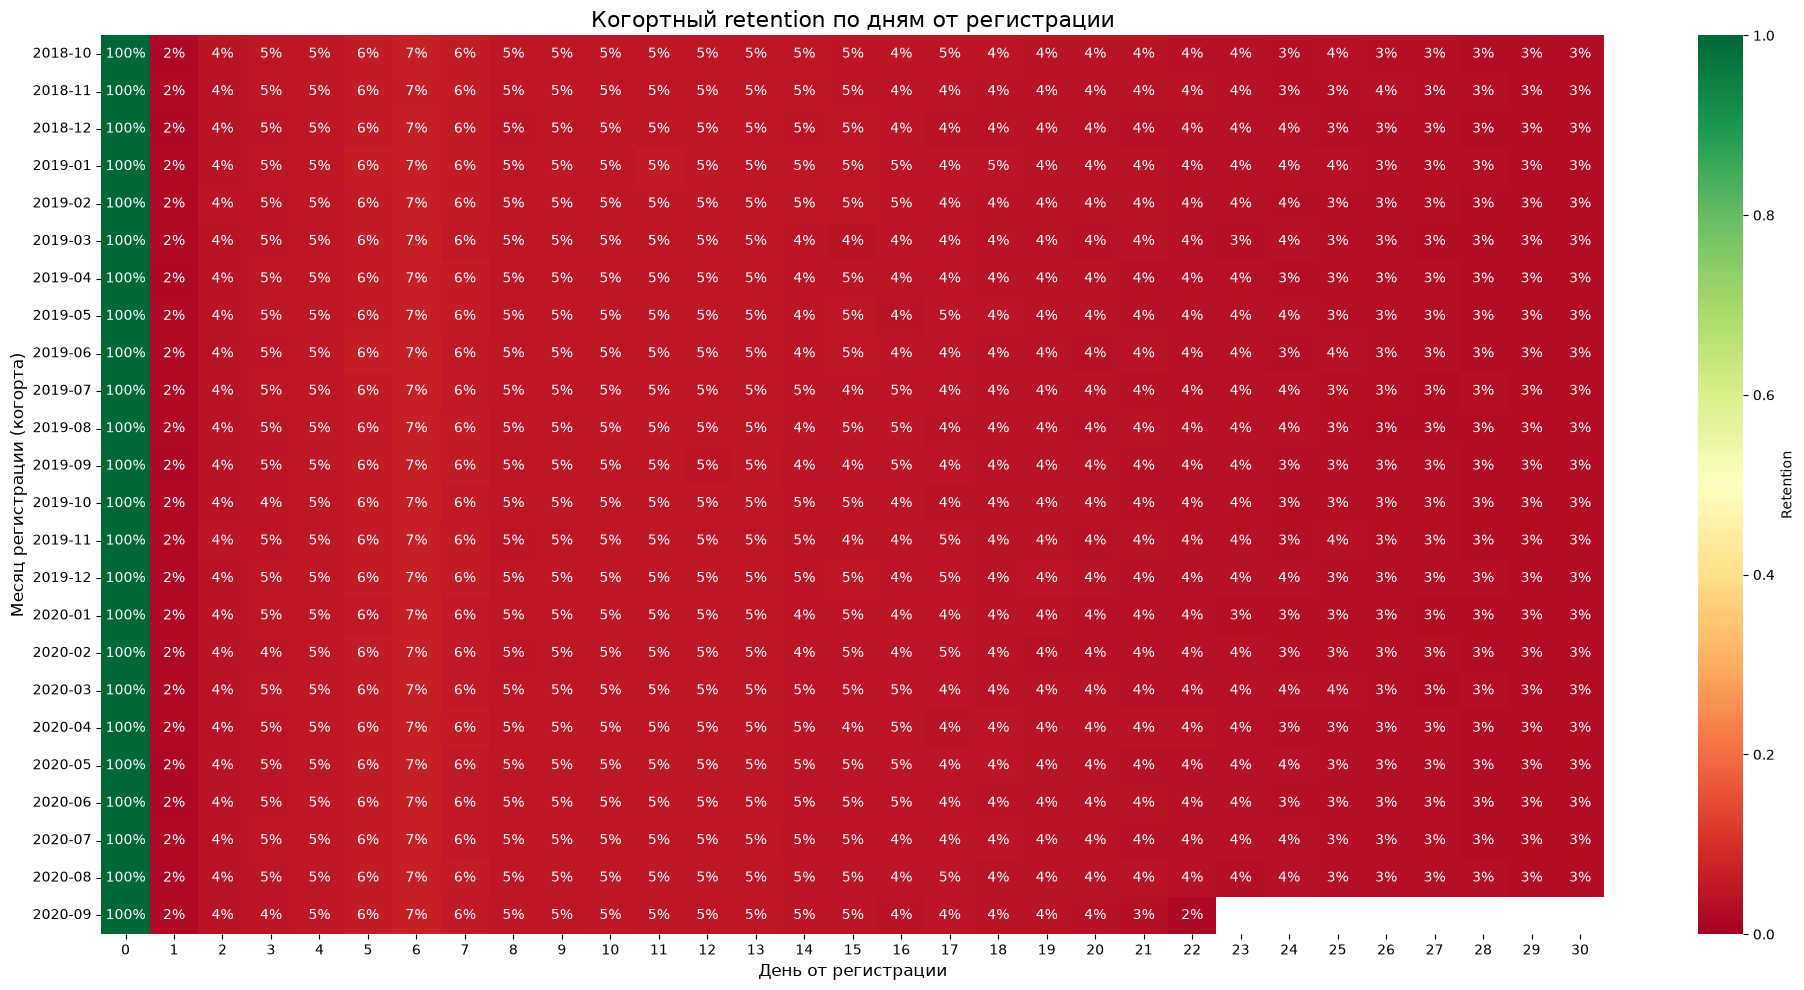

In [41]:
# 1. Матрица в долях 
matrix_full = retention(reg_data, auth_data)

# 2. Ограничиваю столбцы первыми 30 днями (день 0 - 30)
matrix_30 = matrix_full.iloc[:, :31]

# 3. Агрегирую когорты по месяцам: среднее по когортам одного месяца
matrix_monthly = matrix_30.copy()
matrix_monthly.index = matrix_monthly.index.to_period('M')
matrix_monthly = matrix_monthly.groupby(level=0).mean()

# 4. Отбор последних 24 месяцев 
matrix_view = matrix_monthly.tail(24)

print("matrix_view shape:", matrix_view.shape)
print()
print(matrix_view.iloc[:5, :8])

# 5. Тепловая карта
fig, ax = plt.subplots(figsize=(20, 10))

sns.heatmap(
    matrix_view,
    annot=True,           # числа в ячейках
    fmt='.0%',            # формат: 0.021 → "2%"
    cmap='RdYlGn',        # красный (плохо) → зелёный (хорошо)
    mask=matrix_view.isnull(),  # NaN → пустые клетки
    vmin=0, vmax=1,       # фиксированный диапазон цветов
    ax=ax,
    cbar_kws={'label': 'Retention'},
)

ax.set_title('Когортный retention по дням от регистрации', fontsize=16)
ax.set_xlabel('День от регистрации', fontsize=12)
ax.set_ylabel('Месяц регистрации (когорта)', fontsize=12)
plt.tight_layout()
plt.show()

Визуально не очень информативно, т.к. присутствует 0 день. Там всегда 100%, которые нам не дают никакой подезной информации. Поэтому для визуальной наглядности решаю отбросить 0 день, чтобы вернхняя граница градиента сместилась

matrix_view shape: (24, 30)

day_since_reg         1         2         3         4         5         6  \
reg_date                                                                    
2018-10        0.019113  0.041115  0.047121  0.052738  0.060768  0.067903   
2018-11        0.021301  0.042217  0.049662  0.054095  0.060880  0.066381   
2018-12        0.018664  0.039947  0.046078  0.053536  0.060137  0.068946   
2019-01        0.019724  0.039965  0.048449  0.053548  0.063569  0.069488   
2019-02        0.019888  0.043120  0.045540  0.051921  0.062088  0.069396   

day_since_reg         7         8  
reg_date                           
2018-10        0.058958  0.047598  
2018-11        0.061664  0.048577  
2018-12        0.059361  0.046700  
2019-01        0.061407  0.048365  
2019-02        0.061333  0.049277  


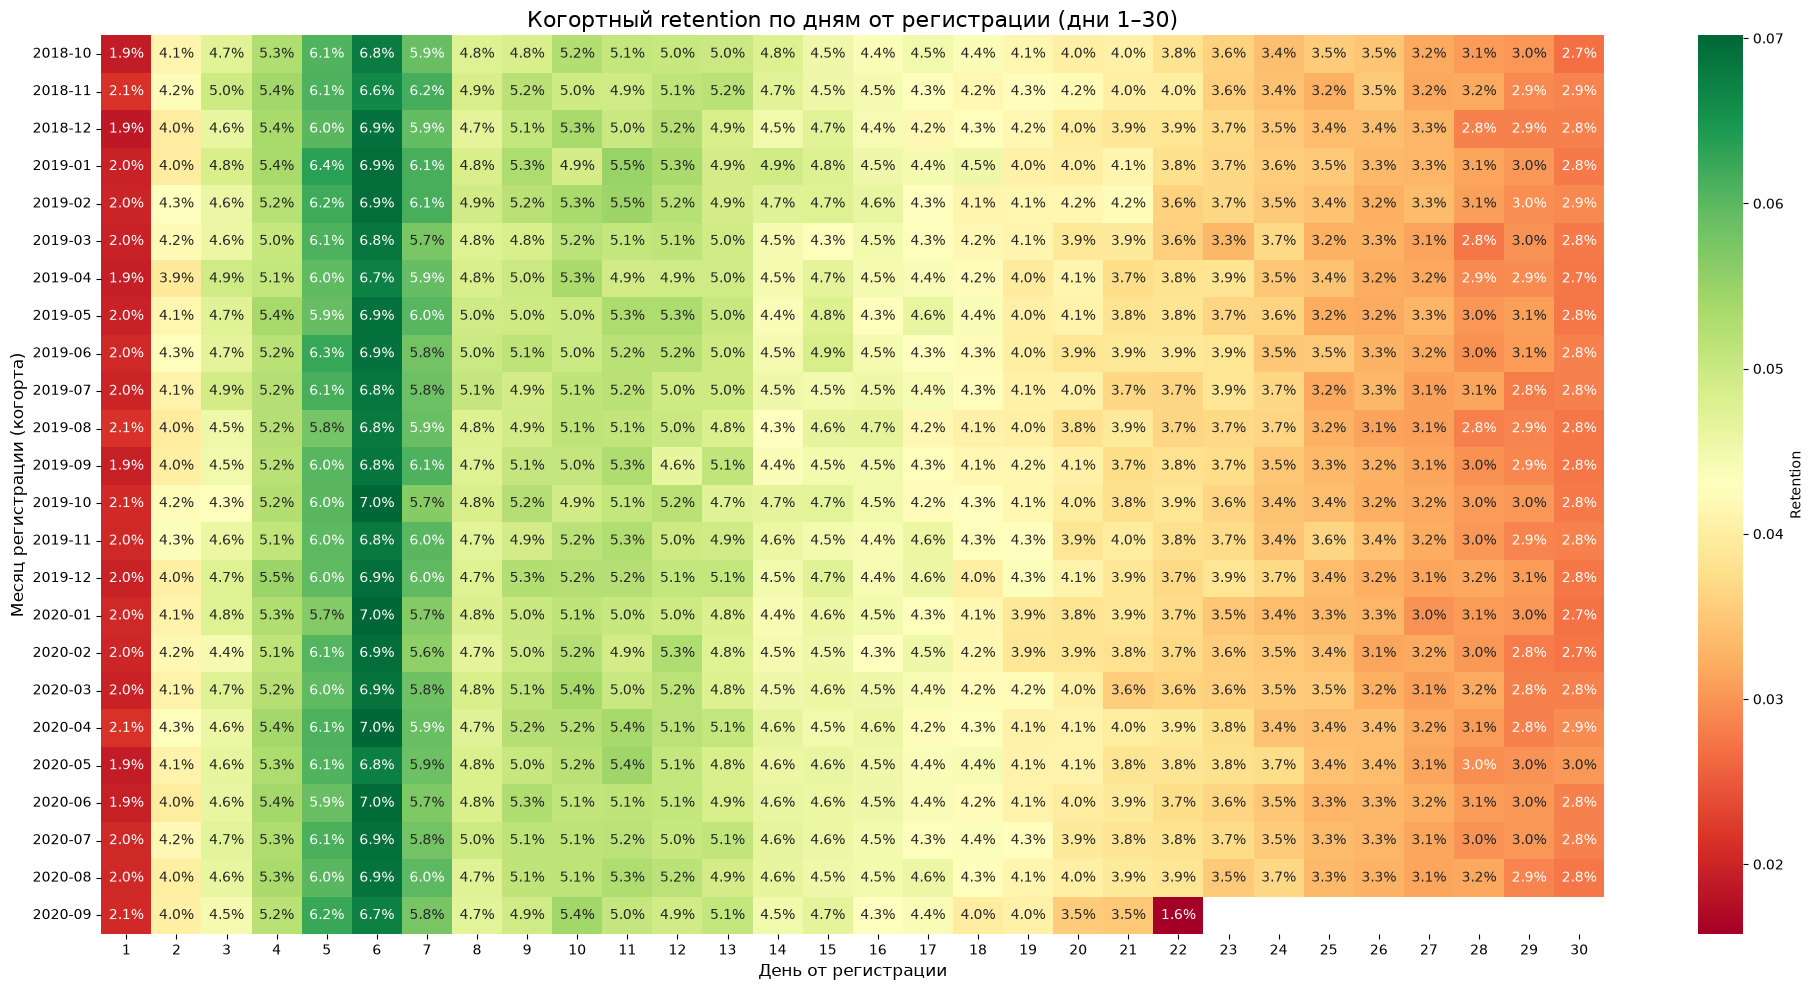

In [42]:
# 1. Матрца в долях
matrix_full = retention(reg_data, auth_data)

# 2. Исключаю день 0 (всегда 100%, не несёт информации)
#    и беру дни 1-30
matrix_30 = matrix_full.iloc[:, 1:31]

# 3. Агрегирую по месяцам
matrix_monthly = matrix_30.copy()
matrix_monthly.index = matrix_monthly.index.to_period('M')
matrix_monthly = matrix_monthly.groupby(level=0).mean()

# 4. Последние 24 месяца
matrix_view = matrix_monthly.tail(24)

print("matrix_view shape:", matrix_view.shape)
print()
print(matrix_view.iloc[:5, :8])

# 5. Тепловая карта
fig, ax = plt.subplots(figsize=(20, 10))

sns.heatmap(
    matrix_view,
    annot=True,
    fmt='.1%',
    cmap='RdYlGn',
    mask=matrix_view.isnull(),
    vmin=matrix_view.min().min(),
    vmax=matrix_view.max().max(), 
    ax=ax,
    cbar_kws={'label': 'Retention'},
)

ax.set_title('Когортный retention по дням от регистрации (дни 1–30)', fontsize=16)
ax.set_xlabel('День от регистрации', fontsize=12)
ax.set_ylabel('Месяц регистрации (когорта)', fontsize=12)
plt.tight_layout()
plt.show()

Стало понятнее. Видно аномальную просадку в 1 же день, а затем рост до пиковых значений к 6 дню и затем снижение

## Выводы по Задаче 1 <a id="section-4"></a>

### Реализация

Написана функция `retention(reg_data, auth_data, start_date=None, end_date=None, day=None, as_percent=False)`, которая считает когортный retention по календарным дням от даты регистрации:

- **Когортный подход:** retention считается отдельно для каждой даты регистрации (когорты)
  - `day=None` — возвращает матрицу retention (когорты × дни);
  - `day=N` — возвращает одно число: средневзвешенный retention N-го дня;
  - `start_date` / `end_date` — ограничивают набор когорт заданным периодом, чтобы функция не считала каждый раз с 1998 года;
  - `as_percent=True` — возвращает значения в процентах вместо долей.
- **Средневзвешенное по когортам:** большие когорты влияют на итог сильнее, что корректнее отражает их вклад в общую метрику, чем просто среднее.
- **NaN и 0:** если когорта уже дожила до соответствующего дня, но в этот день никто не зашёл, это осмысленный ноль, а не отсутствие данных. Поэтому в матрице для таких ячеек стоит 0, а NaN остаётся только там, где когорта физически не могла дойти до этого дня (например, когорта вчерашнего дня и retention 7-го дня).

### Значения retention (на полных данных)

| День | Retention |
|------|-----------|
| D1   | 2.01%     |
| D7   | 5.88%     |
| D30  | 2.83%     |

### Наблюдения

1. **Retention растёт с D1 по D6, затем плавно убывает.**
   Это **нетипичная** картина — обычно retention
   монотонно убывает. Возможные причины:
   - `auth_ts` может фиксировать не все заходы, а, например, первое событие
     за день, и логирование первых дней неполное;
   - возможно, в игре есть механика, стимулирующая возврат на 5–7-й день
     (например, ежедневные бонусы);
   - эффект «выходных»: регистрации в будни, возврат в выходные.

2. **Когорты стабильны между собой.** Паттерн retention повторяется из
   месяца в месяц — данные однородны, нет выбросов и аномальных когорт.

3. **Удержание на длинном горизонте низкое.** К D30 возвращается лишь
   ~3% игроков от исходной когорты.

### Тестирование на сэмпле

Функция протестирована на 10% выборке (100 000 uid из 1 000 000). Значения на сэмпле практически совпали с полными данными: D1 — 2.02% против 2.01%, D7 — 5.88% против 5.88%, D30 — 2.82% против 2.83%. Для итогового анализа используются полные данные.

### Ограничения

- **Средневзвешенное по когортам** даёт одно значение, но не отражает
  распределение retention по разным когортам. Для детального анализа нужна
  вся матрица (возвращается при `day=None`).
- **Столбец D0 всегда равен 100%** по определению (все зарегистрированные
  зашли в день регистрации), поэтому исключён из визуализации.

### Проверка `merge` по `uid`

В функции используется `merge(..., how='left')`, где слева таблица авторизаций. Теоретически это могло потерять пользователей, которые зарегистрировались, но ни разу не зашли в игру. Проверил отдельно:

```python
reg_uids = set(reg_data['uid'])
auth_uids = set(auth_data['uid'])
lost_users = reg_uids - auth_uids
print(f"Зарегистрированы, но ни разу не зашли: {len(lost_users)}")

## Задача 2. A/B тест <a id="section-5"></a>

In [43]:
df_ab

,user_id,revenue,testgroup
0,1,0,b
1,2,0,a
2,3,0,a
3,4,0,b
4,5,0,b
...,...,...,...
404765,404766,0,a
404766,404767,0,b
404767,404768,231,a
404768,404769,0,a


In [44]:
print("Типы данных:")
print(df_ab.dtypes)
print()
print("Пропущенные значения:")
print(df_ab.isna().sum())

Типы данных:
user_id      int64
revenue      int64
testgroup      str
dtype: object

Пропущенные значения:
user_id      0
revenue      0
testgroup    0
dtype: int64


In [45]:
# Проверяю размер групп на соответствие условиям задания
n_a = (df_ab['testgroup'] == 'a').sum()
n_b = (df_ab['testgroup'] == 'b').sum()

print(f"Группа A: {n_a} \nГруппа B: {n_b}")


Группа A: 202103 
Группа B: 202667


In [46]:
# Платящие (revenue > 0)
payers_a = ((df_ab['testgroup'] == 'a') & (df_ab['revenue'] > 0)).sum()
payers_b = ((df_ab['testgroup'] == 'b') & (df_ab['revenue'] > 0)).sum()

In [47]:
# В задании указано: 
# a = 202103 пользователей / 1928 платящих, 
# b = 202667 / 1805
print(f"группа a: {n_a} пользователей, {payers_a} платящих")
print(f"группа b: {n_b} пользователей, {payers_b} платящих")

группа a: 202103 пользователей, 1928 платящих
группа b: 202667 пользователей, 1805 платящих


In [48]:
# Базовые метрики по группам: ARPU, CR, ARPPU.
# ARPU = выручка / все юзеры, CR = платящие / все юзеры, ARPPU = выручка / платящие.
def group_metrics(df, group_name):
    
    sub = df[df['testgroup'] == group_name]
    n_users = len(sub)
    n_payers = (sub['revenue'] > 0).sum()
    total_revenue = sub['revenue'].sum()
    
    arpu = total_revenue / n_users
    cr = n_payers / n_users
    arppu = total_revenue / n_payers if n_payers > 0 else 0
    
    return {
        'группа': group_name,
        'users': n_users,
        'payers': n_payers,
        'total_revenue': total_revenue,
        'ARPU': arpu,
        'CR': cr,
        'ARPPU': arppu,
    }


metrics_a = group_metrics(df_ab, 'a')
metrics_b = group_metrics(df_ab, 'b')

metrics_df = pd.DataFrame([metrics_a, metrics_b]).set_index('группа')
display(metrics_df)

# Насколько B отличается от A в процентах
print("СРАВНЕНИЕ ГРУПП (b vs a)")
print(f"ARPU:  b/a - 1 = {(metrics_b['ARPU'] / metrics_a['ARPU'] - 1) * 100:+.2f}%   (в условии: +5%)")
print(f"CR:    b/a - 1 = {(metrics_b['CR'] / metrics_a['CR'] - 1) * 100:+.2f}%")
print(f"ARPPU: b/a - 1 = {(metrics_b['ARPPU'] / metrics_a['ARPPU'] - 1) * 100:+.2f}%")

,users,payers,total_revenue,ARPU,CR,ARPPU
группа,,,,,,
a,202103,1928,5136189,25.413720,0.009540,2663.998444
b,202667,1805,5421603,26.751287,0.008906,3003.658172


СРАВНЕНИЕ ГРУПП (b vs a)
ARPU:  b/a - 1 = +5.26%   (в условии: +5%)
CR:    b/a - 1 = -6.64%
ARPPU: b/a - 1 = +12.75%


In [49]:
# Анализ распределения выручки в каждой группе
print("РАСПРЕДЕЛЕНИЕ ВЫРУЧКИ (только платящие, revenue > 0)")


for grp in ['a', 'b']:
    sub = df_ab[(df_ab['testgroup'] == grp) & (df_ab['revenue'] > 0)]['revenue']
    print(f"\nГруппа {grp}  (платящих: {len(sub)})")
    print(f"  min:       {sub.min():>10.2f}")
    print(f"  25%:       {sub.quantile(0.25):>10.2f}")
    print(f"  50% (медиана): {sub.median():>10.2f}")
    print(f"  75%:       {sub.quantile(0.75):>10.2f}")
    print(f"  90%:       {sub.quantile(0.90):>10.2f}")
    print(f"  99%:       {sub.quantile(0.99):>10.2f}")
    print(f"  max:       {sub.max():>10.2f}")
    print(f"  mean (ARPPU): {sub.mean():>10.2f}")

print()
print("ТОП-10 ПЛАТЕЖЕЙ В КАЖДОЙ ГРУППЕ")

for grp in ['a', 'b']:
    top10 = df_ab[df_ab['testgroup'] == grp]['revenue'].nlargest(10).values
    print(f"\nГруппа {grp}: {top10}")

РАСПРЕДЕЛЕНИЕ ВЫРУЧКИ (только платящие, revenue > 0)

Группа a  (платящих: 1928)
  min:           200.00
  25%:           257.00
  50% (медиана):     311.00
  75%:           361.00
  90%:           393.30
  99%:         37340.73
  max:         37433.00
  mean (ARPPU):    2664.00

Группа b  (платящих: 1805)
  min:          2000.00
  25%:          2513.00
  50% (медиана):    3022.00
  75%:          3478.00
  90%:          3795.80
  99%:          3981.92
  max:          4000.00
  mean (ARPPU):    3003.66

ТОП-10 ПЛАТЕЖЕЙ В КАЖДОЙ ГРУППЕ

Группа a: [37433 37407 37394 37385 37379 37374 37369 37366 37363 37360]

Группа b: [4000 4000 3999 3999 3995 3995 3995 3993 3993 3992]


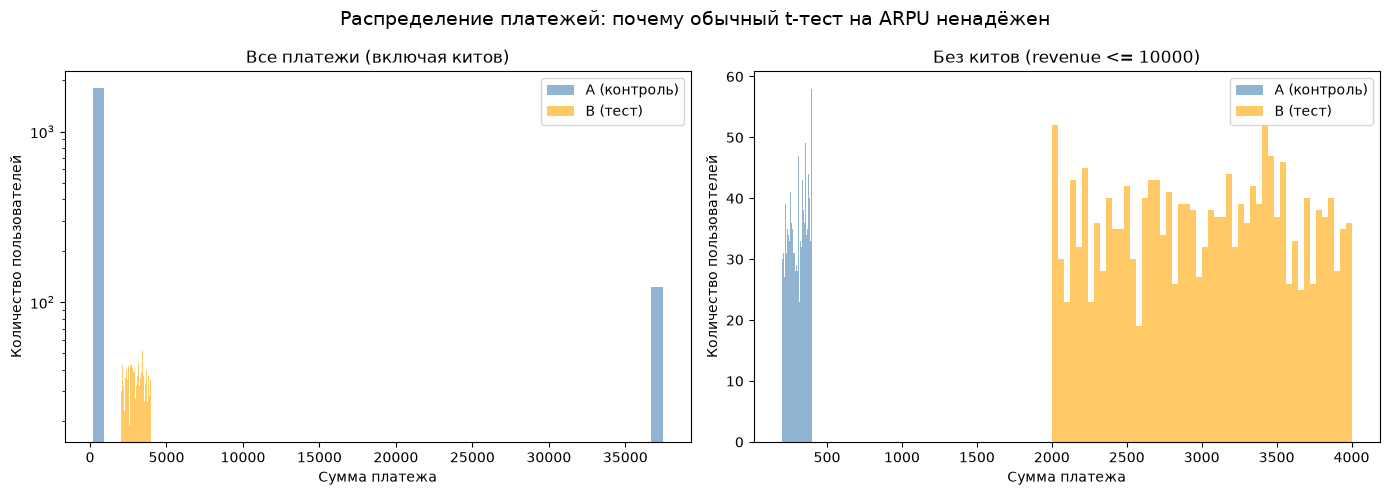

Вывод: в группе A есть длинный правый хвост (киты с платежами до 37 433).
Среднее по A сильно смещено вправо этими выбросами.
В группе B хвоста нет (максимум 4000). Именно поэтому для сравнения ARPU
использован bootstrap — непараметрический метод, устойчивый к тяжёлым хвостам.


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Левый график: все платежи (включая китов) ---
for grp, color, label in [('a', 'steelblue', 'A (контроль)'), ('b', 'orange', 'B (тест)')]:
    data = df_ab[(df_ab['testgroup'] == grp) & (df_ab['revenue'] > 0)]['revenue']
    axes[0].hist(data, bins=50, alpha=0.6, color=color, label=label)
axes[0].set_title('Все платежи (включая китов)')
axes[0].set_xlabel('Сумма платежа')
axes[0].set_ylabel('Количество пользователей')
axes[0].legend()
axes[0].set_yscale('log')  # лог-шкала, чтобы увидеть хвост

# --- Правый график: без китов (revenue <= 10000) ---
THRESHOLD = 10000
for grp, color, label in [('a', 'steelblue', 'A (контроль)'), ('b', 'orange', 'B (тест)')]:
    data = df_ab[(df_ab['testgroup'] == grp) & (df_ab['revenue'] > 0) & (df_ab['revenue'] <= THRESHOLD)]['revenue']
    axes[1].hist(data, bins=50, alpha=0.6, color=color, label=label)
axes[1].set_title(f'Без китов (revenue <= {THRESHOLD})')
axes[1].set_xlabel('Сумма платежа')
axes[1].set_ylabel('Количество пользователей')
axes[1].legend()

plt.suptitle('Распределение платежей: почему обычный t-тест на ARPU ненадёжен', fontsize=14)
plt.tight_layout()
plt.show()

print("Вывод: в группе A есть длинный правый хвост (киты с платежами до 37 433).")
print("Среднее по A сильно смещено вправо этими выбросами.")
print("В группе B хвоста нет (максимум 4000). Именно поэтому для сравнения ARPU")
print("использован bootstrap — непараметрический метод, устойчивый к тяжёлым хвостам.")

### Почему bootstrap, а не t-тест

Обычно для сравнения средних используют t-тест. Он опирается на то, что выборочное среднее распределено приблизительно нормально. На «спокойных» данных это работает хорошо. Но у нас ARPU — это сумма выручки, делённая на число пользователей, и в группе A есть 123 игрока с платежами от 10 000 до 37 433. Эти 123 человека дают около 89% всей выручки группы.

Из-за этого распределение выручки крайне асимметричное, с тяжёлым правым хвостом. Киты редки по доле — около 0.06% всех пользователей группы A (123 из 202 103). Но их вклад в сумму выручки огромен, поэтому выборочное среднее ARPU очень чувствительно к тому, сколько именно китов и с какими суммами попало в выборку. Даже небольшое изменение в наборе китов (на одного больше или меньше, платёж на 5–10 тысяч выше или ниже) сдвигает среднее ARPU на заметную величину. Обычный t-тест в такой ситуации опирается на выборочную дисперсию, которая тоже оценивается неустойчиво из-за тяжёлого хвоста, поэтому доверительный интервал получается ненадёжным. Формально центральная предельная теорема для суммы с тяжёлым хвостом сходится медленно, и на выборке в 200 тысяч пользователей нормальная аппроксимация для среднего ARPU работает плохо.

Bootstrap в этом случае подходящий вариант. Он не предполагает нормальности распределения, а пересэмплирует исходные данные много раз (здесь — 10 000 итераций по всей группе) и смотрит, как ведёт себя разница средних ARPU от итерации к итерации. Этот разброс и даёт эмпирический доверительный интервал, устойчивый к тяжёлым хвостам. Альтернативы:
- t-тест на усечённых средних — отсекает китов, но меняет саму метрику: это уже не ARPU, а усечённое среднее;
- Mann-Whitney U — сравнивает ранги/медианы, а бизнесу нужен именно ARPU, а не медиана;
- z-тест на пропорциях — подходит для CR (доля платящих), но не подходит для ARPU.

Поэтому для ARPU с китами использован bootstrap. Для CR я использовал обычный z-тест на пропорциях: там распределение близко к нормальному за счёт размера выборки, а тяжёлых хвостов нет, потому что CR — это доля, а не сумма выручки.

In [51]:
# Анализ без "китов" — пользователей с платежами > 10000
THRESHOLD = 10000

print(f"Анализ без 'китов' (revenue > {THRESHOLD})")

for grp in ['a', 'b']:
    sub_all = df_ab[df_ab['testgroup'] == grp]
    sub_no_whales = sub_all[sub_all['revenue'] <= THRESHOLD]
    
    n_users = len(sub_no_whales)
    n_payers = (sub_no_whales['revenue'] > 0).sum()
    total_rev = sub_no_whales['revenue'].sum()
    
    print(f"\nГруппа {grp} (без китов):")
    print(f"  users: {n_users}")
    print(f"  payers: {n_payers}")
    print(f"  CR: {n_payers / n_users * 100:.4f}%")
    print(f"  ARPU: {total_rev / n_users:.2f}")
    print(f"  ARPPU: {total_rev / n_payers:.2f}")

print()

print("СКОЛЬКО КИТОВ В КАЖДОЙ ГРУППЕ")

for grp in ['a', 'b']:
    whales = df_ab[(df_ab['testgroup'] == grp) & (df_ab['revenue'] > THRESHOLD)]
    total_from_whales = whales['revenue'].sum()
    total_group = df_ab[df_ab['testgroup'] == grp]['revenue'].sum()
    print(f"\nГруппа {grp}:")
    print(f"  китов: {len(whales)}")
    print(f"  выручка от китов: {total_from_whales:,}")
    print(f"  доля в общей выручке: {total_from_whales / total_group * 100:.2f}%")

Анализ без 'китов' (revenue > 10000)

Группа a (без китов):
  users: 201980
  payers: 1805
  CR: 0.8937%
  ARPU: 2.70
  ARPPU: 302.46

Группа b (без китов):
  users: 202667
  payers: 1805
  CR: 0.8906%
  ARPU: 26.75
  ARPPU: 3003.66

СКОЛЬКО КИТОВ В КАЖДОЙ ГРУППЕ

Группа a:
  китов: 123
  выручка от китов: 4,590,252
  доля в общей выручке: 89.37%

Группа b:
  китов: 0
  выручка от китов: 0
  доля в общей выручке: 0.00%


In [52]:
print("СТАТИСТИЧЕСКИЕ ТЕСТЫ")

# 1. Z-test для CR (все платящие)
print("\n1. Z-test для CR:")
count = np.array([payers_a, payers_b])
nobs = np.array([n_a, n_b])
z_stat, p_value = proportions_ztest(count, nobs)
print(f"   z = {z_stat:.4f}, p-value = {p_value:.4f}")
if p_value < 0.05:
    print("   различие значимо")
else:
    print("   различие НЕ значимо")

# 2. Z-test для CR без китов
print("\n2. Z-test для CR без китов:")
a_nw = df_ab[(df_ab['testgroup'] == 'a') & (df_ab['revenue'] <= THRESHOLD)]
b_nw = df_ab[(df_ab['testgroup'] == 'b') & (df_ab['revenue'] <= THRESHOLD)]

payers_a_nw = (a_nw['revenue'] > 0).sum()
payers_b_nw = (b_nw['revenue'] > 0).sum()

count_nw = np.array([payers_a_nw, payers_b_nw])
nobs_nw = np.array([len(a_nw), len(b_nw)])
z_stat2, p_value2 = proportions_ztest(count_nw, nobs_nw)
print(f"   z = {z_stat2:.4f}, p-value = {p_value2:.4f}")
if p_value2 < 0.05:
    print("   различие значимо")
else:
    print("   различие НЕ значимо")

# 3. Bootstrap для ARPU
print("\n3. Bootstrap для ARPU (10000 итераций):")
np.random.seed(42)

rev_a = df_ab[df_ab['testgroup'] == 'a']['revenue'].values
rev_b = df_ab[df_ab['testgroup'] == 'b']['revenue'].values

diffs = []
for _ in range(10000):
    sample_a = np.random.choice(rev_a, len(rev_a))
    sample_b = np.random.choice(rev_b, len(rev_b))
    diffs.append(sample_b.mean() - sample_a.mean())

diffs = np.array(diffs)
ci_low = np.percentile(diffs, 2.5)
ci_high = np.percentile(diffs, 97.5)
observed = rev_b.mean() - rev_a.mean()

print(f"   разница ARPU (b - a): {observed:.4f}")
print(f"   95% интервал: [{ci_low:.4f}, {ci_high:.4f}]")
if ci_low <= 0 <= ci_high:
    print("   0 внутри интервала -> различие НЕ значимо")
else:
    print("   0 вне интервала -> различие значимо")

СТАТИСТИЧЕСКИЕ ТЕСТЫ

1. Z-test для CR:
   z = 2.1080, p-value = 0.0350
   различие значимо

2. Z-test для CR без китов:
   z = 0.1025, p-value = 0.9184
   различие НЕ значимо

3. Bootstrap для ARPU (10000 итераций):
   разница ARPU (b - a): 1.3376
   95% интервал: [-2.9702, 5.4522]
   0 внутри интервала -> различие НЕ значимо


In [53]:
# Собираю итоговую таблицу по группам
rows = []
for grp in ['a', 'b']:
    m = metrics_df.loc[grp]
    pay = df_ab[df_ab['testgroup'] == grp]['revenue']
    pay = pay[pay > 0]
    total = m['total_revenue']

    whales = pay[pay > THRESHOLD].sum()
    top1 = pay.nlargest(max(1, int(len(pay) * 0.01))).sum()

    rows.append([
        int(m['users']),
        int(m['payers']),
        int(total),
        round(m['ARPU'], 2),
        f"{m['CR'] * 100:.3f}%",
        int(round(m['ARPPU'])),
        int(pay.median()),
        int(pay.max()),
        f"{whales / total * 100:.1f}%",
        f"{top1 / total * 100:.1f}%",
    ])

summary = pd.DataFrame(
    rows,
    index=['Группа A (контроль)', 'Группа B (тест)'],
    columns=[
        'Пользователей', 'Платящих', 'Общая выручка', 'ARPU', 'CR', 'ARPPU',
        'Медиана платежа', 'Максимальный платёж',
        f'Доля выручки китов (>{THRESHOLD})',
        'Доля выручки топ-1% платящих',
    ]
).T

display(summary)

,Группа A (контроль),Группа B (тест)
Пользователей,202103,202667
Платящих,1928,1805
Общая выручка,5136189,5421603
ARPU,25.41,26.75
CR,0.954%,0.891%
ARPPU,2664,3004
Медиана платежа,311,3022
Максимальный платёж,37433,4000
Доля выручки китов (>10000),89.4%,0.0%
Доля выручки топ-1% платящих,13.8%,1.3%


## Выводы по задаче 2 <a id="section-6"></a>

### Какой набор предложений лучше?

Короткий ответ: **оба варианта рабочие, но у них разные риски**. Ни один из тестов не показал статистически значимого роста метрик в группе B: ARPU вырос лишь описательно (bootstrap-интервал включает ноль), а CR по всем платящим значимо снизился (p=0.035) и сравнялся с A только после исключения китов. Поэтому однозначно рекомендовать B нельзя.

**Набор A (контроль)** — «китовая» модель. 123 игрока с платежами > 10 000 приносят 89.4% всей выручки группы. Остальные платят по 200–400 рублей (медиана 311). Потенциал дохода высокий, но вся выручка висит на маленькой группе людей. Если киты уйдут — выручка A обвалится примерно на 90%, до ~0.55 млн.

**Набор B (тест)** — «массовая» модель. Максимальный платёж 4000, китов в группе нет. Зато типичный (медианный) платёж в 10 раз больше, чем в A (3022 против 311). Выручка не зависит от отдельных крупных платежей — она гораздо стабильнее.

### Какие метрики важны и почему

1. **ARPU и ARPPU.** Смотреть только на ARPU нельзя: в A среднее раздуто китами. Поэтому для сравнения ARPU использован **bootstrap** (см. пояснение выше), а не t-тест.
2. **Bootstrap для ARPU:** 95% доверительный интервал разницы `[−2.97; +5.45]` включает ноль. Значит, рост ARPU в B **статистически незначим** — он может быть случайным.
3. **CR (конверсия в платящего):** по всем платящим CR в B значимо ниже, чем в A: 0.891% против 0.954% (p=0.035). То есть значимое различие есть, но это не рост B, а его отставание. После исключения китов разница исчезает: 0.8906% в B против 0.8937% в A, p=0.918 — статистически незначимо. Число платящих после исключения китов совпадает — по 1805 в каждой группе. В A 1928 платящих, в B 1805; разница ровно 123 — столько же, сколько китов в A. Значит, «лишние» 123 платящих в A — это и есть киты, а без них CR почти совпадает.
4. **Медиана платежа:** 311 в A против 3022 в B. Это реальный эффект новой механики, а не выбросы.
5. **Концентрация выручки:** в A киты дают 89.4% выручки, в B — 0%. Даже топ-1% платящих в A даёт 13.8% выручки, а в B — только 1.3%. То есть A держится на нескольких людях.

### Запускать ли B на всех?

**Пока нет — тест нужно продлить и доработать.** 

По имеющимся данным нельзя утверждать, что B лучше A. ARPU в B выше описательно (+5.26%), но bootstrap-интервал разницы [−2.97; +5.45] включает ноль, поэтому рост статистически незначим. CR в B значимо ниже по всем платящим (p=0.035), а после исключения китов разница исчезает (p=0.918). То есть подтверждённого значимого улучшения в B нет: мы можем сказать, что B не хуже A по ARPU и не хуже по CR без китов, но не можем сказать, что он лучше. Для финального решения тест стоит продлить и оценить MDE (минимальный обнаруживаемый эффект) — то есть понять, какой рост метрик тест способен поймать при текущей дисперсии. Если реальный эффект меньше MDE, его не увидит и продлённый тест.

**План действий:**
1. Продлить тест и пересчитать MDE с учётом реальной дисперсии.
2. Добавить в механику B VIP-предложения для крупных плательщиков.
3. Запустить B на новых игроках (без китов), чтобы не потерять текущих крупных плательщиков A.
4. По результатам продлённого теста принимать финальное решение.

## Задача 3. Метрики тематического события в игре Plants & Gardens <a id="section-7"></a>

По последнему событию я бы смотрел метрики не одним списком, а по группам — иначе цифр много, а понять, что именно сработало, сложно. И почти все метрики имеют смысл только в сравнении: с контрольной группой, с периодом до события или с прошлым похожим ивентом. Для Plants & Gardens логично сравнивать с предыдущим тематическим событием того же типа и длительности.

### 1. Вовлечённость

- **Event Participation Rate** — доля игроков, зашедших в событие, от DAU за период события. Показывает, какой охват получил ивент.
- **Глубина вовлечения** — среднее время в событии за сессию и число сессий на игрока. Если участников много, а время маленькое, возможно, люди просто заходят посмотреть и уходят.
- **DAU/MAU за период события** — выросла ли активность в игре в целом, а не только внутри события.

### 2. Прогресс и сложность

- **Completion Rate** — доля игроков, дошедших до финальной награды. Если он низкий, механика может быть слишком сложной или долгой.
- **Воронка прохождения** — на каком уровне отваливается больше всего игроков. Так можно найти конкретное «бутылочное горлышко», а не ругать событие целиком.
- **Time-to-complete** — медианное время прохождения. Если оно сильно больше комфортного окна, игроки могут выгорать.

### 3. Монетизация

- **CR и ARPU участников события** по сравнению с неучастниками или контрольной группой. Смотреть именно на разницу, а не на абсолютные значения.
- **Revenue от события** — продажи уникальных предметов для сада, персонажей, монет, бустов и пропусков уровней.
- **Доля выручки события в общей выручке игры** за период.

### 4. Удержание и долгосрочный эффект

- **Retention D1/D7/D30 участников события** по сравнению с контрольной группой или неучастниками. Важно, чтобы событие удерживало в игре, а не только внутри ивента.
- **Возврат в основной геймплей** после окончания события — играют ли люди дальше или ждут следующего ивента.

---

### Что меняется, если добавить откат уровней

Если при неудаче игрок откатывается на несколько уровней назад, набор метрик заметно меняется. Появляется фактор фрустрации, и **Completion Rate** перестаёт быть главной метрикой. Он в такой механике и так упадёт — это ожидаемо. Важнее понять, как игроки реагируют на неудачу.

### Отказы и фрустрация

- **Количество откатов на игрока** — как часто люди теряют прогресс.
- **Доля игроков, столкнувшихся с откатом хотя бы раз** — насколько широко механика задевает аудиторию.
- **Dropout rate после первого отката** — сколько игроков закрывают событие или игру сразу после потери прогресса. Это уже похоже на «rage quit» и напрямую влияет на удержание.

### Повторные попытки

- **Среднее число попыток** пройти уровень после отката. Если оно низкое, люди не готовы мириться с потерей прогресса.
- **Доля вернувшихся к уровню после отката** — более мягкий вариант: сколько игроков вообще готовы попробовать снова.
- **Time-to-complete** — ожидаемо вырастет. Нужно следить, чтобы прохождение не превращалось в марафон и не выходило за комфортное окно.

### Монетизация

- Появляется новый триггер — **покупки, чтобы избежать отката**: страховки, бусты, дополнительные жизни. Отдельно стоит смотреть **конверсию в платёж после неудачи**. Если она высокая, надо проверить, не выглядит ли это как навязанная механика или pay-to-win.
- **ARPPU** может вырасти за счёт продажи страховок, но **ARPU** при этом может упасть, если фрустрированные игроки уходят из игры. Рост среднего чека сам по себе не означает, что событие стало лучше.

### Удержание

- Механика с откатом может **снизить Retention** из-за высокого порога входа. Корректнее сравнивать когорту участников нового события с участниками прошлых, более лёгких событий.
- **Churn rate в дни после события** — не приводит ли стресс от потери прогресса к уходу из игры в целом, а не только из ивента.

Если коротко: при откате уровней главное — смотреть не на Completion Rate, а на баланс между сложностью и фрустрацией. Сколько откатов получает игрок, сколько людей уходит после первого отката, готовы ли они пробовать снова и не превращается ли монетизация в продажу «страховок от неудачи». Если краткосрочно выручка растёт, но падает удержание и растёт churn — это плохой размен, и по одним только Completion Rate или ARPU его не видно.